# Phân tích cảm xúc đánh giá sản phẩm Điện Máy Xanh
## Notebook báo cáo thực nghiệm — phiên bản tái lập

**Học phần:** Phân tích và Khai phá Dữ liệu Văn bản · **Bài toán:** phân loại cảm xúc tiếng Việt thành Negative / Neutral / Positive.

Notebook này được thiết kế vừa là sổ tay chạy pipeline vừa là khung báo cáo có thể xuất HTML/PDF. Cấu trúc trình bày gồm bối cảnh, dữ liệu, phương pháp, thực nghiệm, đánh giá theo lớp, phân tích lỗi, giới hạn và kết luận; mức chi tiết được mở rộng để giải thích lựa chọn phương pháp và diễn giải kết quả thay vì chỉ chép bảng điểm.

> **Lưu ý khoa học quan trọng:** `data/processed/test.csv` hiện được tách phân tầng nhưng nhãn `label_target` được tạo bởi quy tắc hybrid từ rating + lexicon, **chưa phải nhãn vàng do người gán độc lập**. Do đó các điểm số dưới đây đo mức khớp với nhãn tự động trên tập giữ lại, không phải ước lượng độ chính xác tuyệt đối với cảm xúc thật. Không gọi tập này là “gold test” trong báo cáo. Có script xuất mẫu mù để tạo tập người gán: `scripts/export_annotation_sample.py`.

> Chạy từ thư mục gốc repo. Lệnh huấn luyện nặng được tắt mặc định; bật các cờ trong phần “Chạy thực nghiệm” khi đã cài đủ thư viện / có GPU. Notebook không tự bịa kết quả: các bảng điểm chỉ xuất hiện khi file metrics đã được sinh.


## 1. Tóm tắt nghiên cứu

**Mục tiêu.** Xây dựng pipeline có thể tái lập để phân loại bình luận thiết bị gia dụng thành ba cực tính; so sánh biểu diễn từ vựng (BoW, TF-IDF, Word2Vec) kết hợp mô hình cổ điển (Naïve Bayes, Linear SVM) với fine-tuning Transformer tiếng Việt và đa ngôn ngữ.

**Câu hỏi nghiên cứu.** (RQ1) TF-IDF có cải thiện Macro-F1 so với BoW không? (RQ2) Linear SVM có tốt hơn Naïve Bayes trên dữ liệu lệch lớp không? (RQ3) Fine-tuning PhoBERT và XLM-RoBERTa có cải thiện nhóm Neutral/Negative hay không? (RQ4) Sai số chủ yếu phát sinh ở lớp nào và do đâu?

**Tiêu chí chính.** Macro-F1 trên validation để lựa chọn mô hình; báo cáo Accuracy, Macro-Precision/Recall/F1, Weighted-F1, per-class precision/recall/F1, confusion matrix và khoảng tin cậy bootstrap 95% trên held-out test. Khi có nhãn người gán, báo cáo thêm Cohen’s kappa và đánh giá độc lập với pseudo-label.


## 2. Môi trường và thiết lập

Cài dependency tại thư mục dự án bằng `pip install -r requirements.txt`. Để chạy notebook: `jupyter lab notebooks/01_sentiment_analysis_report.ipynb`. Seed mặc định là 42; mọi vectorizer/Word2Vec chỉ fit trên train. Transformer dùng validation để early stopping / chọn checkpoint và chỉ chấm test sau cùng.


In [1]:
from pathlib import Path
import json, os, sys, subprocess, textwrap, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

# Xác định thư mục gốc dù notebook được mở từ Jupyter tại root hoặc notebooks/.
CANDIDATES = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in CANDIDATES if (p / "data/processed/train.csv").exists()), Path.cwd())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
DATA = ROOT / "data/processed"
METRICS_DIR = ROOT / "outputs/metrics"
PRED_DIR = ROOT / "outputs/predictions"
FIG_DIR = ROOT / "figures"
SEED = 42
LABEL_NAMES = {-1: "Negative", 0: "Neutral", 1: "Positive"}
plt.rcParams.update({"figure.figsize": (9, 5), "axes.titlesize": 13, "font.size": 10})
pd.set_option("display.max_colwidth", 180)
print(f"Project root: {ROOT}")


Project root: /home/user/dmx-nlp-sentiment


## 3. Dữ liệu và quy trình tạo nhãn

Dữ liệu được crawl từ trang đánh giá sản phẩm Điện Máy Xanh. Quy trình tiền xử lý chuẩn hóa Unicode/teencode, loại rác và trùng lặp, tách từ tiếng Việt, bảo toàn từ phủ định/cảm xúc, sau đó kết hợp rating với lexicon và quy tắc phủ định/liên từ chuyển ý để tạo `label_target`. Rating ban đầu được ánh xạ 1–2 sao → Negative, 3 sao → Neutral, 4–5 sao → Positive; các trường hợp xung đột mạnh có thể được hiệu chỉnh theo nội dung.

Bảng mô tả dưới đây đọc trực tiếp từ các tệp hiện có. Nên đưa số lượng bị loại và quy tắc vào báo cáo cuối cùng, đồng thời kiểm tra thủ công mẫu xung đột trước khi khẳng định độ tin cậy của nhãn.


In [2]:
split_paths = {name: DATA / f"{name}.csv" for name in ["train", "val", "test"]}
missing = [str(p) for p in split_paths.values() if not p.exists()]
if missing:
    raise FileNotFoundError(f"Missing processed splits: {missing}. Run `python auto_label_review.py` first.")
splits = {name: pd.read_csv(path).fillna("") for name, path in split_paths.items()}
for name, frame in splits.items():
    frame["label_target"] = frame["label_target"].astype(int)
    print(f"{name}: {len(frame):,} rows; columns={list(frame.columns)}")

summary_path = ROOT / "data/interim/labeling_summary.json"
labeling_summary = json.loads(summary_path.read_text(encoding="utf-8")) if summary_path.exists() else {}
summary = pd.DataFrame([
    {"split": name, "rows": len(frame), "unique_reviews": frame.get("review_id", pd.Series(dtype=str)).nunique(),
     "positive share": (frame.label_target == 1).mean(), "neutral share": (frame.label_target == 0).mean(),
     "negative share": (frame.label_target == -1).mean()}
    for name, frame in splits.items()
]).set_index("split")
display(summary.round(3))
print("Labeling summary:", {k: labeling_summary.get(k) for k in ["raw_total_rows", "valid_unique_rows", "skipped_invalid", "skipped_duplicate", "total_conflicts_adjusted", "mode"]})


train: 7,664 rows; columns=['review_id', 'category', 'product_code', 'rating', 'content', 'text_segmented', 'text_clean', 'label_star', 'label_target', 'conflict_type']
val: 1,352 rows; columns=['review_id', 'category', 'product_code', 'rating', 'content', 'text_segmented', 'text_clean', 'label_star', 'label_target', 'conflict_type']
test: 500 rows; columns=['review_id', 'category', 'product_code', 'rating', 'content', 'text_segmented', 'text_clean', 'label_star', 'label_target', 'conflict_type']


,rows,unique_reviews,positive share,neutral share,negative share
split,,,,,
train,7664,7664,0.682,0.064,0.255
val,1352,1352,0.682,0.064,0.254
test,500,500,0.640,0.120,0.240


Labeling summary: {'raw_total_rows': 12189, 'valid_unique_rows': 9516, 'skipped_invalid': 49, 'skipped_duplicate': 2624, 'total_conflicts_adjusted': 490, 'mode': 'hybrid-lexicon'}


In [3]:
# Integrity checks: ensure no review_id overlaps. Product overlap is reported (not assumed to be an error).
for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    fa, fb = splits[a], splits[b]
    if "review_id" in fa and "review_id" in fb:
        overlap = set(fa.review_id) & set(fb.review_id)
        assert not overlap, f"Leakage: {len(overlap)} repeated review IDs between {a} and {b}"
    content_a = set(fa.content.astype(str).str.strip().str.lower())
    content_b = set(fb.content.astype(str).str.strip().str.lower())
    exact_text_overlap = len((content_a & content_b) - {""})
    products = len(set(fa.get("product_code", [])) & set(fb.get("product_code", [])))
    print(f"{a} vs {b}: exact-text overlap={exact_text_overlap}; shared products={products}")
print("Review-ID disjointness checks passed. Product-level separation is not enforced in the current random stratified split.")


train vs val: exact-text overlap=28; shared products=207
train vs test: exact-text overlap=17; shared products=142
val vs test: exact-text overlap=1; shared products=116
Review-ID disjointness checks passed. Product-level separation is not enforced in the current random stratified split.


### 3.1 Phân bố nhãn, rating và ngành hàng

Lớp Positive thường chiếm đa số và Neutral là lớp thiểu số, vì vậy Accuracy đơn lẻ có thể che khuất mô hình dự đoán kém lớp hiếm. Macro-F1 cho trọng số bằng nhau đối với từng lớp. Các phân bố thực tế được vẽ bên dưới để đưa thẳng vào chương mô tả dữ liệu.


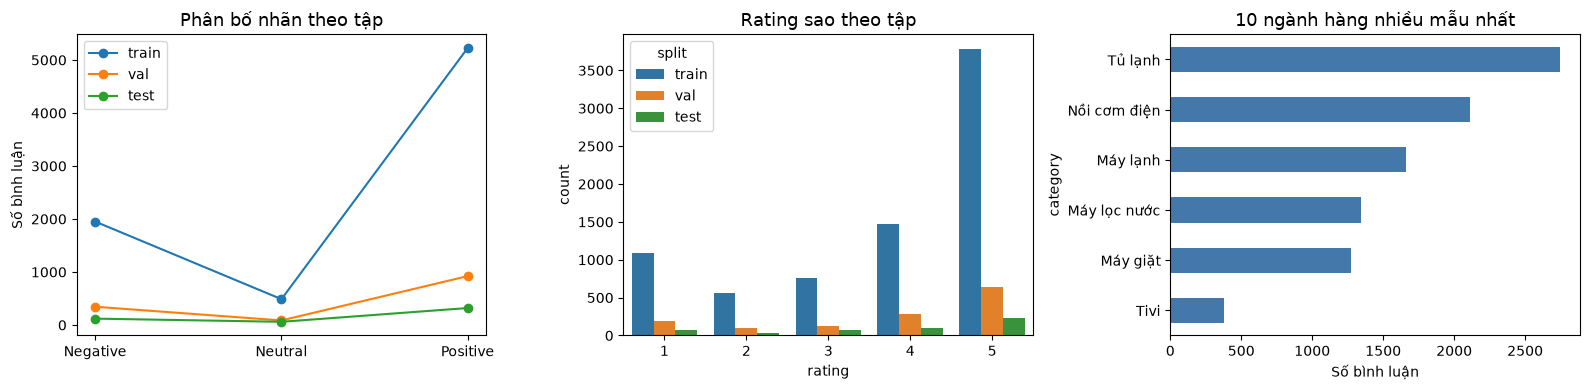

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
order = [-1, 0, 1]
for name, frame in splits.items():
    counts = frame.label_target.value_counts().reindex(order, fill_value=0)
    axes[0].plot([LABEL_NAMES[i] for i in order], counts.values, marker="o", label=name)
axes[0].set_title("Phân bố nhãn theo tập")
axes[0].set_ylabel("Số bình luận")
axes[0].legend()
all_df = pd.concat([f.assign(split=n) for n, f in splits.items()], ignore_index=True)
if "rating" in all_df:
    sns.countplot(data=all_df, x="rating", hue="split", ax=axes[1])
    axes[1].set_title("Rating sao theo tập")
if "category" in all_df:
    cat = all_df.category.value_counts().head(10)
    cat.sort_values().plot.barh(ax=axes[2], color="#4477aa")
    axes[2].set_title("10 ngành hàng nhiều mẫu nhất")
    axes[2].set_xlabel("Số bình luận")
plt.tight_layout(); plt.show()


### 3.2 Chất lượng tiền xử lý và xung đột sao–văn bản

Bản `text_segmented` giữ ngữ cảnh và stopword phù hợp PhoBERT; `text_clean` lọc stopword cho đặc trưng cổ điển. Cần tránh loại bỏ từ phủ định như “không/chưa” vì có thể đảo chiều cảm xúc. Các biểu đồ sau là dữ liệu quan sát, không phải kết quả mô hình.


In [5]:
sample = all_df.drop_duplicates("review_id").head(8) if "review_id" in all_df else all_df.head(8)
cols = [c for c in ["content", "text_segmented", "text_clean", "rating", "label_target"] if c in sample]
display(sample[cols])
conflict_path = ROOT / "data/interim/rating_text_conflicts.csv"
if conflict_path.exists():
    conflicts = pd.read_csv(conflict_path).fillna("")
    print(f"Flagged rating-text conflicts: {len(conflicts):,}")
    if "conflict_type" in conflicts:
        display(conflicts.conflict_type.value_counts().rename_axis("conflict_type").to_frame("count"))
        display(conflicts[[c for c in ["rating", "content", "conflict_type", "label_star", "label_target"] if c in conflicts]].head(10))
else:
    conflicts = pd.DataFrame()
    print("No conflict report found; run auto_label_review.py.")


,content,text_segmented,text_clean,rating,label_target
0,Tủ mới mua đc 2 ngày tại dmx. Có hiện tượng tuyết và mồ hôi trong ngăn mát cả ngăng đông,tủ mới mua được 2 ngày tại điện_máy_xanh có hiện tượng tuyết và mồ hôi trong ngăn mát cả ngăng đông,tủ mua ngày điện_máy_xanh có hiện tượng tuyết mồ hôi ngăn mát cả ngăng đông,3,1
1,mới sử dụng thấy sp tốt nếu sử dung thêm 1 thời gian nữa sp chạy vẩn ok thì giới thiệu bạn bè mua,mới sử_dụng thấy sản_phẩm tốt nếu sử dung thêm 1 thời_gian nữa sản_phẩm chạy vẩn tốt thì giới thiệu bạn bè mua,sử_dụng thấy sản_phẩm tốt sử dung thêm thời_gian sản_phẩm chạy vẩn tốt giới thiệu bè mua,5,1
2,"Nồi tốt, mẫu mã đẹp.","nồi tốt, mẫu mã đẹp.",nồi tốt mẫu mã đẹp,5,1
3,"Nồi cơm lòng sâu, tốt","nồi_cơm lòng sâu, tốt",nồi_cơm lòng sâu tốt,4,1
4,"Nhân viên tư vấn nhiệt tình, giao hàng nhanh, tủ rất đẹp sang trọng, tiết kiệm điện, bảo quản thức phẩm rất tốt. Rất hài lòng về sản phẩm. 👍","nhân_viên tư_vấn nhiệt_tình, giao_hàng nhanh, tủ rất đẹp sang_trọng, tiết_kiệm_điện, bảo quản thức phẩm rất tốt. rất hài_lòng về sản_phẩm.",nhân_viên tư_vấn nhiệt_tình giao_hàng nhanh tủ rất đẹp sang_trọng tiết_kiệm_điện bảo quản thức phẩm rất tốt rất hài_lòng sản_phẩm,5,1
5,"Tủ đẹp, mặt gương nhìn sang xịn mịn. Lạnh khá nhanh và sâu. Tủ chạy êm ko ồn nhiều. Tạm thời cảm nhận vậy còn dùng lâu mới biết được có lỗi hay ko, độ bền ra sao.","tủ đẹp, mặt gương nhìn sang xịn mịn. lạnh khá nhanh và sâu. tủ chạy êm không ồn nhiều. tạm thời cảm nhận vậy còn dùng lâu mới biết được có lỗi hay không độ bền ra sao.",tủ đẹp mặt gương nhìn sang xịn mịn lạnh khá nhanh sâu tủ chạy êm không ồn tạm thời cảm nhận dùng lâu biết có lỗi không độ bền sao,5,1
6,"Máy sài tốt , tiết kiệm điện","máy xài tốt , tiết_kiệm_điện",máy xài tốt tiết_kiệm_điện,5,1
7,Dùng tối uy tín,dùng tối uy tín,dùng tối uy tín,5,1


Flagged rating-text conflicts: 490


,count
conflict_type,
star_3_clear_negative,294
star_pos_text_strong_negative,79
star_3_clear_positive,67
star_4_mixed_contrast_to_neutral,41
star_neg_text_strong_positive,9


,rating,content,conflict_type,label_star,label_target
0,4,"Nhìn chung cũng ok. Nhưng có điều là tìm kiếm bằng giọng nói hơi lag. Mới mở tv lên tìm không được, tầm vài phút sài mới được chức năng này. Không biết có cách nào khác phục kh...",star_4_mixed_contrast_to_neutral,1,0
1,4,"Máy giặt dùng tốt, giặt quần áo sạch, nhưng khi giặt theo chế độ hay bị lỗi chữ E",star_4_mixed_contrast_to_neutral,1,0
2,4,"Em cần thanh lý lại con nồi này ạ, em nấu cơm được 5-6 lần thôi nên còn mới chán =)))) New 95% luôn í ạ, nồi dùng rất tốt nhưng rất tiếc nó to hơn em tưởng nên nấu có 2 lít cơm...",star_4_mixed_contrast_to_neutral,1,0
3,4,Cũng được nhưng khi vắt rung kêu,star_pos_text_strong_negative,1,-1
4,4,"Tủ hơi bị lệch cửa. Tạm ổn, có cái dây nguồn gây thất vọng dây nhỏ chui thươg, thua dây tủ cùi bắp củ....",star_pos_text_strong_negative,1,-1
5,4,"Máy chạy êm,hơi tệ là mặt gương lúc nào nhìn vào thays dơ cần khắc phục",star_pos_text_strong_negative,1,-1
6,4,"Máy có bơm hút sâu, mạnh. Bơm đầu ra cũng mạnh. Mỗi tội kêu to, nhiều lúc giật cả mình",star_pos_text_strong_negative,1,-1
7,4,"Ngăn đông mềm linh hoạt Optimal Fresh+, Công nghệ SpaceMax tăng thêm dung tích sử dụng, tủ chạy không êm, quạt chạy còn kêu tiếng",star_pos_text_strong_negative,1,-1
8,4,"ngăn đồng dùng không tốt lắm,",star_pos_text_strong_negative,1,-1
9,4,"Máy dùng tốt, khả năng đông đá nhanh nhưng hoạt động còn hơi ồn",star_4_mixed_contrast_to_neutral,1,0


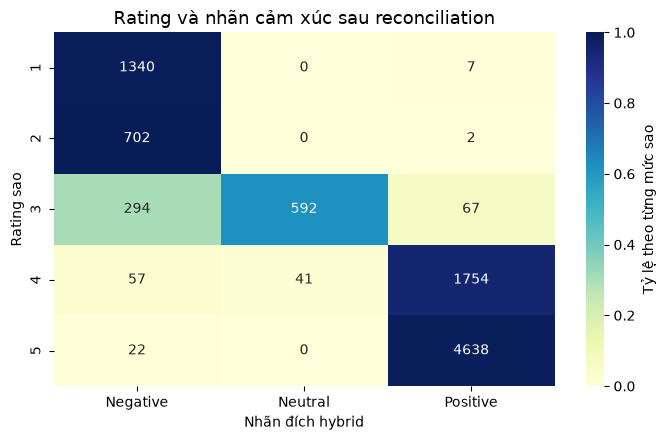

In [6]:
# Rating-to-target cross-tab: shows precisely where the semantic auto-label differs from star bins.
if "rating" in all_df and "label_target" in all_df:
    rating_target = pd.crosstab(all_df["rating"], all_df["label_target"]).reindex(columns=[-1, 0, 1], fill_value=0)
    row_pct = rating_target.div(rating_target.sum(axis=1), axis=0)
    fig, ax = plt.subplots(figsize=(7, 4.5))
    sns.heatmap(row_pct, annot=rating_target, fmt="d", cmap="YlGnBu", cbar_kws={"label": "Tỷ lệ theo từng mức sao"},
                xticklabels=[LABEL_NAMES[x] for x in [-1, 0, 1]], ax=ax, vmin=0, vmax=1)
    ax.set(xlabel="Nhãn đích hybrid", ylabel="Rating sao", title="Rating và nhãn cảm xúc sau reconciliation")
    plt.tight_layout(); plt.show()


## 4. Phương pháp và thiết kế thực nghiệm

### 4.1 Baselines và đặc trưng
- **Majority baseline:** luôn chọn lớp phổ biến nhất; mốc tối thiểu để chứng minh các mô hình học được tín hiệu.
- **BoW / TF-IDF:** unigram + bigram; fit vocabulary/IDF chỉ trên train.
- **Word2Vec Skip-gram:** huấn luyện trên train, lấy mean pooling; GaussianNB dùng cho vector dense có thể âm.
- **Multinomial Naïve Bayes:** phù hợp đặc trưng đếm/TF-IDF; **LinearSVC:** `class_weight=balanced` cho lệch lớp.

### 4.2 Mô hình Transformer hiện đại
- **PhoBERT (`vinai/phobert-base-v2`):** encoder tiền huấn luyện tiếng Việt, fine-tune end-to-end trên chuỗi đã word-segment.
- **XLM-RoBERTa Large (`FacebookAI/xlm-roberta-large`):** encoder đa ngôn ngữ dung lượng lớn, nhận nội dung tiếng Việt nguyên bản không bắt buộc word segmentation; dùng làm đối chứng hiện đại có năng lực cao hơn. Đây là đối chứng mạnh, không tự động đồng nghĩa “SOTA” nếu chưa benchmark cùng protocol / dữ liệu.
- Cả hai dùng weighted cross-entropy với $w_c=N/(K N_c)$, validation Macro-F1 để chọn checkpoint, early stopping và test giữ lại. So sánh compute và giới hạn bộ nhớ được ghi nhận cùng điểm số.

### 4.3 Thiết kế đánh giá
Mọi model dùng cùng train/validation/test và cùng `label_target`; không so sánh validation theo rating thô với test theo nhãn đã hiệu chỉnh. Ưu tiên Macro-F1 do mất cân bằng; báo cáo thêm per-class, confusion matrix, 95% bootstrap CI. Vì test hiện mang pseudo-label, CI chỉ phản ánh bất định lấy mẫu với nhãn hiện tại, không khắc phục sai lệch annotation.


## 5. Chạy thực nghiệm (tuỳ chọn)

Mặc định không huấn luyện lại. Đổi `RUN_CLASSICAL=True` để chạy toàn bộ baselines cổ điển. Để fine-tune transformer, thêm tên model vào `TRANSFORMER_MODELS`. XLM-R Large thường cần GPU nhiều VRAM; giảm batch-size hoặc max-length nếu hết bộ nhớ. Tải checkpoint Hugging Face cần internet. Mỗi lệnh lưu metrics, dự đoán và confusion matrix vào `outputs/` / `figures/`.


In [7]:
RUN_CLASSICAL = False
TRANSFORMER_MODELS = []  # Ví dụ: ["vinai/phobert-base-v2", "FacebookAI/xlm-roberta-large"]

if RUN_CLASSICAL:
    subprocess.run([sys.executable, str(ROOT / "scripts/train_classical.py")], cwd=ROOT, check=True)
for model_name in TRANSFORMER_MODELS:
    cmd = [sys.executable, str(ROOT / "scripts/train_transformer.py"), "--model-name", model_name]
    if model_name.endswith("xlm-roberta-large"):
        cmd += ["--batch-size", "2", "--gradient-accumulation-steps", "8", "--max-length", "160"]
    subprocess.run(cmd, cwd=ROOT, check=True)
print("RUN_CLASSICAL =", RUN_CLASSICAL, "| transformer runs =", TRANSFORMER_MODELS)


RUN_CLASSICAL = False | transformer runs = []


## 6. Kết quả định lượng

Cell sau thu thập mọi JSON metrics đã được sinh bởi scripts. Nếu chưa chạy huấn luyện thì bảng trống là trạng thái đúng; không chèn số liệu tham khảo từ repo khác. Chọn mô hình theo validation Macro-F1; held-out test chỉ dùng để báo cáo cuối, không tinh chỉnh lặp dựa trên test.


In [8]:
metric_records = []
if METRICS_DIR.exists():
    for path in sorted(METRICS_DIR.glob("*.json")):
        try:
            payload = json.loads(path.read_text(encoding="utf-8"))
        except (json.JSONDecodeError, OSError):
            continue
        records = payload if isinstance(payload, list) else [payload]
        for record in records:
            if isinstance(record, dict) and "macro_f1" in record:
                record = dict(record); record.setdefault("metrics_file", str(path.relative_to(ROOT)))
                metric_records.append(record)
metrics_df = pd.DataFrame(metric_records)
if metrics_df.empty:
    print("Chưa có kết quả. Bật RUN_CLASSICAL hoặc chạy scripts/train_transformer.py.")
else:
    keep = [c for c in ["model", "model_name", "accuracy", "macro_precision", "macro_recall", "macro_f1", "weighted_f1", "validation_macro_f1", "test_macro_f1_ci95", "metrics_file"] if c in metrics_df]
    if "model" not in metrics_df and "model_name" in metrics_df: metrics_df["model"] = metrics_df.model_name
    display(metrics_df[keep].sort_values("macro_f1", ascending=False).reset_index(drop=True))


,model,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,validation_macro_f1,test_macro_f1_ci95,metrics_file
0,Word2Vec + LinearSVC,0.828,0.6941,0.7038,0.6949,0.8246,0.7125,"[0.6467, 0.7445]",outputs/metrics/classical_metrics.json
1,BoW + MultinomialNB,0.814,0.6742,0.6878,0.6790,0.8136,0.6897,"[0.6305, 0.727]",outputs/metrics/classical_metrics.json
2,BoW + LinearSVC,0.818,0.6906,0.6576,0.6632,0.8022,0.6799,"[0.6144, 0.71]",outputs/metrics/classical_metrics.json
3,TF-IDF + LinearSVC,0.830,0.6827,0.6688,0.6626,0.8130,0.6912,"[0.6182, 0.7116]",outputs/metrics/classical_metrics.json
4,TF-IDF + MultinomialNB,0.818,0.6578,0.6500,0.6378,0.7999,0.6905,"[0.5936, 0.6881]",outputs/metrics/classical_metrics.json
5,Word2Vec + GaussianNB,0.736,0.6060,0.6392,0.6119,0.7567,0.6065,"[0.5703, 0.6593]",outputs/metrics/classical_metrics.json
6,Majority baseline,0.640,0.2133,0.3333,0.2602,0.4995,0.2703,"[0.249, 0.2703]",outputs/metrics/classical_metrics.json


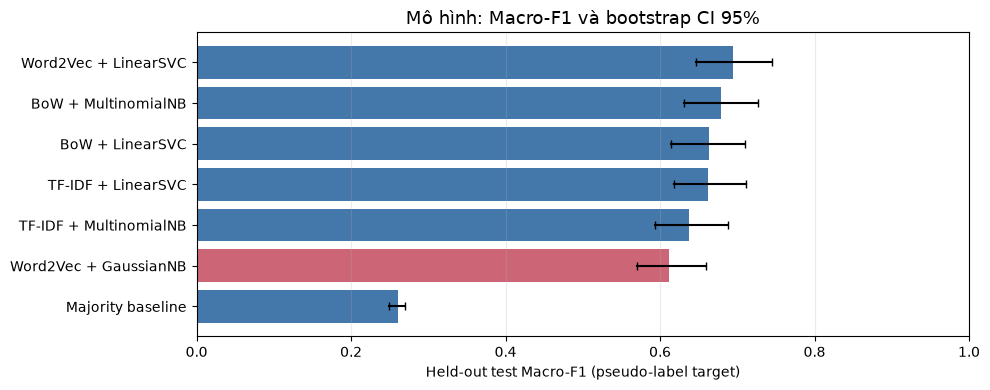

In [9]:
if not metrics_df.empty:
    chart = metrics_df.copy()
    chart["model_label"] = chart.get("model", chart.get("model_name", "model"))
    chart = chart.sort_values("macro_f1")
    fig, ax = plt.subplots(figsize=(10, max(4, 0.5 * len(chart))))
    colors = ["#cc6677" if "validation_macro_f1" in chart.columns and pd.notna(v) and v < s else "#4477aa"
              for v, s in zip(chart.get("validation_macro_f1", pd.Series(np.nan, index=chart.index)), chart.macro_f1)]
    ax.barh(chart.model_label, chart.macro_f1, color=colors)
    if "test_macro_f1_ci95" in chart:
        for i, (_, row) in enumerate(chart.iterrows()):
            ci = row.test_macro_f1_ci95
            if isinstance(ci, list) and len(ci) == 2:
                ax.plot(ci, [i, i], color="black", linewidth=1.5); ax.plot(ci, [i, i], "|", color="black")
    ax.set(xlim=(0, 1), xlabel="Held-out test Macro-F1 (pseudo-label target)", title="Mô hình: Macro-F1 và bootstrap CI 95%")
    ax.grid(axis="x", alpha=.25); plt.tight_layout(); plt.show()


## 7. Phân tích theo lớp và confusion matrix

Điểm tổng hợp không cho biết mô hình bỏ sót lớp nào. Bảng theo lớp dưới đây đặc biệt quan trọng với Neutral (ít mẫu) và Negative (liên quan trực tiếp tới cảnh báo lỗi sản phẩm). Ma trận nhầm lẫn giúp phân biệt lỗi Neutral→Positive (đánh giá nhẹ bị hiểu thành khen) với Negative→Neutral (phàn nàn yếu / lexicon bỏ sót).


Model selected by validation Macro-F1 where available: Word2Vec + LinearSVC


,precision,recall,f1,support
Negative,0.7241,0.8750,0.7925,120.0
Neutral,0.4167,0.3333,0.3704,60.0
Positive,0.9414,0.9031,0.9219,320.0


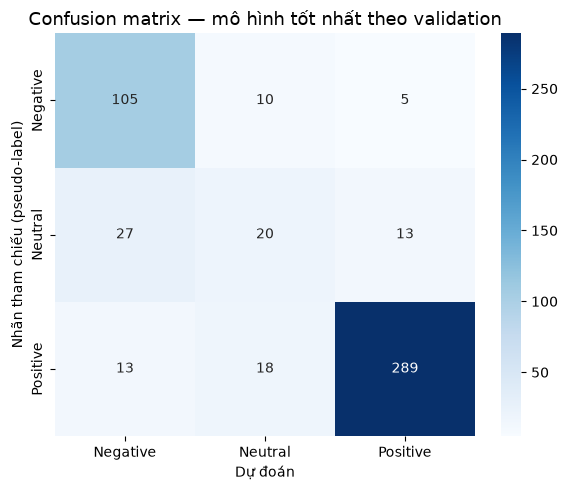

In [10]:
if not metrics_df.empty:
    best = metrics_df.sort_values("validation_macro_f1", ascending=False, na_position="last").iloc[0] if "validation_macro_f1" in metrics_df else metrics_df.sort_values("macro_f1", ascending=False).iloc[0]
    print("Model selected by validation Macro-F1 where available:", best.get("model", best.get("model_name", "unknown")))
    if isinstance(best.get("per_class"), dict):
        per_class = pd.DataFrame(best["per_class"]).T
        display(per_class)
    if isinstance(best.get("confusion_matrix"), list):
        cm = np.asarray(best["confusion_matrix"])
        fig, ax = plt.subplots(figsize=(6, 5))
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=[LABEL_NAMES[x] for x in [-1,0,1]],
                    yticklabels=[LABEL_NAMES[x] for x in [-1,0,1]], ax=ax)
        ax.set(xlabel="Dự đoán", ylabel="Nhãn tham chiếu (pseudo-label)", title="Confusion matrix — mô hình tốt nhất theo validation")
        plt.tight_layout(); plt.show()
    else:
        print("Selected metrics record has no confusion matrix")


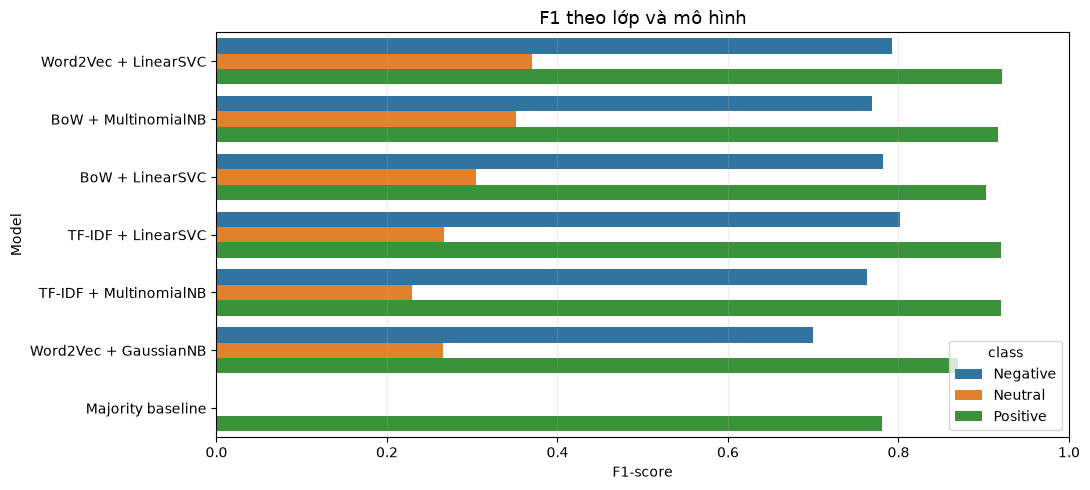

In [11]:
# Per-class F1 is essential because aggregate scores can conceal weak Neutral performance.
if not metrics_df.empty:
    per_rows = []
    for _, record in metrics_df.iterrows():
        model_label = record.get("model", record.get("model_name", "model"))
        for class_name, values in (record.get("per_class") or {}).items():
            per_rows.append({"model": model_label, "class": class_name, "f1": values["f1"]})
    per_f1 = pd.DataFrame(per_rows)
    fig, ax = plt.subplots(figsize=(11, max(5, 0.55 * per_f1.model.nunique())))
    sns.barplot(data=per_f1, y="model", x="f1", hue="class", order=metrics_df.sort_values("macro_f1", ascending=False).get("model"), ax=ax)
    ax.set(xlim=(0, 1), xlabel="F1-score", ylabel="Model", title="F1 theo lớp và mô hình")
    ax.grid(axis="x", alpha=.25); plt.tight_layout(); plt.show()


## 8. Phân tích lỗi định tính

Đọc các trường hợp dự đoán sai để phát hiện lỗi hệ thống: đảo phủ định, lời khen/chê mỉa mai, nội dung hỗn hợp, vấn đề giao hàng/bảo hành, câu quá ngắn hoặc lexicon thiếu từ miền. Ví dụ trích dưới đây lấy từ prediction CSV do script huấn luyện tạo ra, có nhãn tham chiếu là nhãn tự động; cần người đánh giá trước khi đưa nguyên văn vào báo cáo.


In [12]:
if not metrics_df.empty:
    best_record = best.to_dict()
    pred_file = best_record.get("prediction_file")
    pred_path = ROOT / pred_file if isinstance(pred_file, str) else None
    if pred_path and pred_path.exists():
        pred_df = pd.read_csv(pred_path).fillna("")
        errors = pred_df[pred_df.y_true.astype(int) != pred_df.y_pred.astype(int)].copy()
        errors["reference"] = errors.y_true.astype(int).map(LABEL_NAMES)
        errors["prediction"] = errors.y_pred.astype(int).map(LABEL_NAMES)
        print(f"Misclassified: {len(errors):,}/{len(pred_df):,} ({len(errors)/max(len(pred_df),1):.1%})")
        if "category" in errors:
            display(errors.groupby(["reference", "prediction", "category"]).size().sort_values(ascending=False).head(12).rename("count").to_frame())
        display(errors[[c for c in ["content", "reference", "prediction", "category"] if c in errors]].head(25))
    else:
        print("Prediction CSV not found for chosen model. Re-run the training script to export row-level errors.")
else:
    print("Run at least one model to generate prediction-level error analysis.")


Misclassified: 86/500 (17.2%)


count
reference prediction category           
Neutral   Negative   Nồi cơm điện      8
                     Máy lọc nước      7
                     Máy lạnh          5
Positive  Negative   Máy lạnh          5
          Neutral    Nồi cơm điện      5
                     Máy lạnh          4
Neutral   Negative   Tủ lạnh           4
Negative  Neutral    Nồi cơm điện      4
Neutral   Positive   Tủ lạnh           4
Negative  Positive   Tủ lạnh           3
Neutral   Negative   Máy giặt          3
Positive  Negative   Máy lọc nước      3

,content,reference,prediction,category
0,Tạm ổn mới nắp mà,Positive,Neutral,Máy lạnh
6,Mọi người sử dụng có bị tróc si lòng nồi k chứ sao e mới Sài vài tháng mà tróc lớp si cho dù Sài rất kĩ không dùng vật gì chùi rửa có hình mà xóa mất tiêu,Neutral,Negative,Nồi cơm điện
10,Vừa dùng nên chưa biết tốt hay k nhưng tạm nói là ok,Neutral,Positive,Tủ lạnh
22,Tôi mua 9/2024 c Vy chăm sóc khánh hàng và a Thi kỹ thuật quá nhiệt tình và kỹ năng sử lý vấn đề tốt phản ánh về việc đc ưu đãi thay 3 lõi lọc cứ đmx đổi cho nhân viên khi mua ...,Positive,Negative,Máy lọc nước
24,Đẹp,Neutral,Positive,Nồi cơm điện
25,"Tủ sài êm 10 ngày đầu. Tủ có lúc chạy rất ồn mở cửa ngăn đá nghe như máy dầu chạy, rút điện để khoang 15 phút ghim lại thì chạy êm",Negative,Positive,Tủ lạnh
26,"Sài đc 1 tuần cảm nhận máy lạnh êm rất đáng đồng tiền , làm lạnh nhanh rất ok , giao hàng đúng hẹn , thợ lắp nhiệt tình, tuy nhiên nhân viên bán hàng tại st không nhiệt tình kh...",Neutral,Positive,Máy lạnh
27,"tủ lạnh nhà em , mở ngăn mát ra , bóng đèn chóp liên tục là bị sao thế .mong phản hồi ạh",Positive,Neutral,Tủ lạnh
30,Cho mình hỏi thấy có khuyến mãi tham gia chương trình bốc thăm của Daikin. Nhưng hôm giao máy bên bộ phận giao k nói j hết. Với lại bên lắp ráp k phải nhân viên điện máy xanh. ...,Positive,Neutral,Máy lạnh
32,Không tin tưởng hãng nào khác ngoài toshiba,Positive,Negative,Tủ lạnh


## 9. Tạo tập nhãn người gán và đánh giá độ đồng thuận

Pseudo-labels không thay thế gold labels. Xuất mẫu phân tầng, ẩn nhãn tự động, yêu cầu ít nhất hai người gán độc lập với hướng dẫn nhất quán (Negative/Neutral/Positive), sau đó adjudicate bất đồng. Tính Cohen’s kappa giữa annotator 1 và 2, confusion matrix của model so với nhãn adjudicated, và Macro-F1 trên tập con đã audit. Dùng mẫu test độc lập, không dùng để tune.

Chạy từ terminal: `python scripts/export_annotation_sample.py --n 300 --seed 42`. Có thể truyền `--sampling random` nếu cần giữ tỷ lệ prevalence; mẫu stratified ưu tiên lớp hiếm nên không đại diện prevalence thô nếu không hiệu chỉnh trọng số. Hoàn tất các cột `annotator_1_label`, `annotator_2_label`, `adjudicated_label` trong CSV xuất ra. Cell dưới đây tính kappa / model evaluation nếu file đã hoàn thành.


In [13]:
annotation_path = ROOT / "outputs/annotation/annotation_sheet.csv"
if annotation_path.exists():
    ann = pd.read_csv(annotation_path).dropna(subset=["annotator_1_label", "annotator_2_label", "adjudicated_label"])
    if len(ann):
        from sklearn.metrics import cohen_kappa_score, classification_report
        a1 = ann.annotator_1_label.astype(int); a2 = ann.annotator_2_label.astype(int)
        ann["adjudicated_label"] = ann.adjudicated_label.astype(int)
        print("Inter-annotator Cohen's kappa:", round(cohen_kappa_score(a1, a2, labels=[-1,0,1]), 4))
        if not metrics_df.empty and isinstance(best.get("prediction_file"), str):
            prediction_path = ROOT / best["prediction_file"]
            if prediction_path.exists():
                audited = ann.merge(pd.read_csv(prediction_path)[["review_id", "y_pred"]], on="review_id", how="inner")
                if len(audited):
                    print(f"Human-audited model test rows: {len(audited)}")
                    print(classification_report(audited.adjudicated_label.astype(int), audited.y_pred.astype(int), labels=[-1,0,1], target_names=["Negative","Neutral","Positive"], zero_division=0))
                else:
                    print("No overlap between audited review IDs and stored model predictions.")
            else:
                print("No prediction artifact available for human-audited evaluation.")
        else:
            print("Run a model first to compare its predictions with the adjudicated labels.")
    else:
        print("Annotation sheet exists but labels are not filled in yet.")
else:
    print("No completed human annotation file yet. Export one with scripts/export_annotation_sample.py.")


No completed human annotation file yet. Export one with scripts/export_annotation_sample.py.


## 10. Thảo luận, giới hạn và kết luận

### Diễn giải cần đưa vào báo cáo
1. Nêu model tốt nhất trên validation Macro-F1, sau đó báo cáo test một lần cùng CI và per-class scores; không khẳng định chênh lệch có ý nghĩa nếu CI chồng lấp.
2. So sánh BoW vs TF-IDF, NB vs SVM, Word2Vec vs sparse n-grams; giải thích dựa trên confusion matrix, không chỉ dựa vào điểm tổng.
3. Đối chiếu PhoBERT và XLM-R Large theo Macro-F1, lớp Neutral/Negative, thời gian / GPU / max length. Không gọi một mô hình là SOTA nếu chưa có benchmark công bằng trên nhãn người gán và cùng protocol.
4. Phân tích lỗi tiêu biểu, ghi nhận các trường hợp lexicon hoặc rating gây nhiễu.

### Hạn chế
- Nhãn train/validation/test hiện do quy tắc hybrid sinh ra, có thể tạo vòng lặp khi mô hình học lại logic của lexicon; kết quả hiện chỉ là pseudo-label agreement.
- Lấy mẫu ngẫu nhiên giữ lại một số sản phẩm ở nhiều tập; nếu mục tiêu là tổng quát hóa sang sản phẩm chưa thấy, cần đánh giá bổ sung theo group split (`product_code`).
- Dataset bị lệch lớp, bao quát hạn chế theo thời gian / sản phẩm / phong cách viết; quy tắc sentiment có thể bỏ sót mỉa mai và câu nhiều khía cạnh.
- XLM-R Large tốn tài nguyên; so sánh phải nêu GPU, seed, thời gian huấn luyện, phiên bản thư viện và checkpoint.

### Kết luận (điền sau khi chạy)
Notebook tổng hợp một pipeline có thể tái lập từ dữ liệu thô đến so sánh mô hình. Bản kết luận cuối cùng cần thay thế nhận định chung bằng các số đo thực tế do các cell trên sinh ra và ưu tiên xác thực bằng tập test được người gán độc lập.


## Phụ lục A — Các lệnh chạy độc lập

```bash
python auto_label_review.py
python scripts/train_classical.py --bootstrap 2000
python scripts/train_transformer.py --model-name vinai/phobert-base-v2 --epochs 5
python scripts/train_transformer.py --model-name FacebookAI/xlm-roberta-large --batch-size 2 --gradient-accumulation-steps 8 --max-length 160
python scripts/export_annotation_sample.py --n 300
```

**Tham khảo định dạng trình bày:** báo cáo `docs/Bài Tập Lớn I - Lazada.pdf`. Các biểu đồ trong `figures/reference/` chỉ là hình tham khảo từ repo khác cùng chủ đề, không được dùng làm kết quả của bộ dữ liệu này. Notebook này sử dụng số liệu / biểu đồ sinh mới từ các lần chạy của dự án.
